# ICA Assignment 14

**Name**: Wajahat Hussain Sangi    
**ERPID**: 37283


**Program:** BS Economics


---

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


---
## Dataset 1: Pakistani E-Commerce Data
**File:** `pakistani_ecommerce_dataset.csv`

In [15]:
# 1. Load the dataset using Python
df_ecom = pd.read_csv('pakistani_ecommerce_dataset.csv')
df_ecom.head()

,user_id,gender,age_group,city,product_category,payment_method,order_value,order_status
0,U001,Male,25-34,Islamabad,Home Decor,JazzCash,1899.62,Pending
1,U002,Female,25-34,Lahore,Electronics,EasyPaisa,1592.21,Cancelled
2,U003,Female,25-34,Lahore,Books,Debit Card,3851.78,Cancelled
3,U004,Female,18-24,Lahore,Home Decor,Cash on Delivery,1774.12,Pending
4,U005,Female,35-44,Lahore,Home Decor,EasyPaisa,3611.28,Cancelled


### Q1: Which is the most popular product category?

In [16]:
category_counts = df_ecom['product_category'].value_counts()
print(category_counts)
print(f"\nMost popular product category: {category_counts.idxmax()} ({category_counts.max()} orders)")

product_category
Home Decor     30
Clothing       22
Beauty         19
Electronics    18
Books          11
Name: count, dtype: int64

Most popular product category: Home Decor (30 orders)


**Answer (Q1):** **Home Decor** is the most popular product category with **30 orders** (out of 100 total orders).

### Q2: What is the average order value?

In [17]:
avg_order_value = df_ecom['order_value'].mean()
print(f"Average Order Value: PKR {avg_order_value:,.2f}")

Average Order Value: PKR 2,832.15


**Answer (Q2):** The average order value is **PKR 2,832.15**.

### Q3: Which city has the highest number of orders?

In [18]:
city_counts = df_ecom['city'].value_counts()
print(city_counts)
print(f"\nCity with highest number of orders: {city_counts.idxmax()} ({city_counts.max()} orders)")

city
Karachi       24
Islamabad     21
Rawalpindi    20
Lahore        18
Faisalabad    17
Name: count, dtype: int64

City with highest number of orders: Karachi (24 orders)


**Answer (Q3):** **Karachi** has the highest number of orders with **24 orders**.

### Q4: What is the most used payment method?

In [19]:
payment_counts = df_ecom['payment_method'].value_counts()
print(payment_counts)
print(f"\nMost used payment method: {payment_counts.idxmax()} ({payment_counts.max()} orders)")

payment_method
Cash on Delivery    29
JazzCash            27
EasyPaisa           23
Debit Card          21
Name: count, dtype: int64

Most used payment method: Cash on Delivery (29 orders)


**Answer (Q4):** **Cash on Delivery** is the most used payment method with **29 orders**.

### Q5: Draw a bar chart showing average order value by city.

         city  order_value
0   Islamabad  3011.951429
1     Karachi  2956.497917
2  Faisalabad  2937.084118
3      Lahore  2785.330000
4  Rawalpindi  2447.075500


/tmp/ipykernel_500/276343238.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=avg_by_city, x='city', y='order_value', palette='viridis')


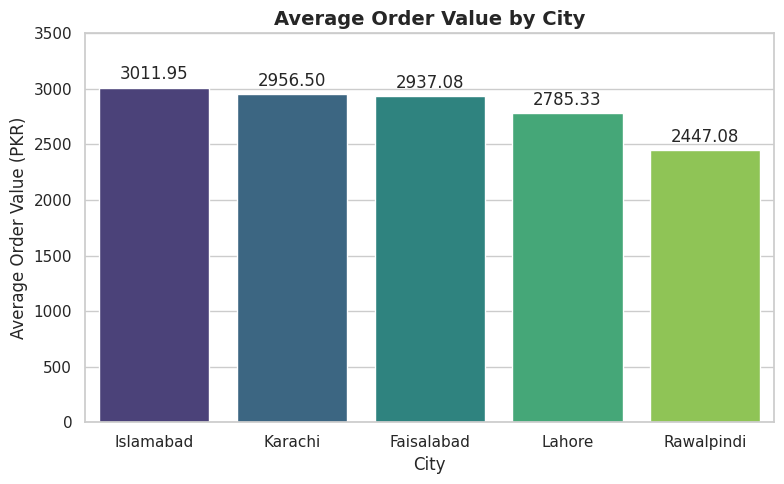

In [20]:
avg_by_city = df_ecom.groupby('city')['order_value'].mean().sort_values(ascending=False).reset_index()
print(avg_by_city)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=avg_by_city, x='city', y='order_value', palette='viridis')
plt.title('Average Order Value by City', fontsize=14, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Average Order Value (PKR)', fontsize=12)
plt.ylim(0, 3500)

# Add value labels on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

**Observation (Q5):** **Islamabad** leads in average order value at **PKR 3,011.95**, followed closely by **Karachi** (**PKR 2,956.50**) and **Faisalabad** (**PKR 2,937.08**).

---
## Dataset 2: Student Lifestyle & Study Habits
**File:** `student_lifestyle_dataset.csv`

In [21]:
# Load the dataset using Python
df_student = pd.read_csv('student_lifestyle_dataset.csv')
df_student.head()

,student_id,gender,study_hours,sleep_hours,screen_time,internet_usage,daily_transport_cost
0,S001,Female,7.0,7.1,2.7,9.3,102.0
1,S002,Female,4.9,6.9,2.9,1.0,284.0
2,S003,Female,5.9,8.9,5.3,5.2,123.0
3,S004,Female,3.2,4.2,1.8,5.2,73.0
4,S005,Male,1.8,5.0,2.5,6.1,202.0


### Q1: What is the average number of study hours?

In [22]:
avg_study_hours = df_student['study_hours'].mean()
print(f"Average Study Hours: {avg_study_hours:.2f} hours/day")

Average Study Hours: 4.40 hours/day


**Answer (Q1):** The average number of study hours is **4.40 hours** per day.

### Q2: Who sleeps more on average — males or females?

In [23]:
avg_sleep_gender = df_student.groupby('gender')['sleep_hours'].mean()
print(avg_sleep_gender)
print(f"\nGroup that sleeps more on average: {avg_sleep_gender.idxmax()} ({avg_sleep_gender.max():.2f} hours)")

gender
Female    6.796154
Male      6.389583
Name: sleep_hours, dtype: float64

Group that sleeps more on average: Female (6.80 hours)


**Answer (Q2):** **Females** sleep more on average (**6.80 hours**) compared to **Males** (**6.39 hours**).

### Q3: Is there a relationship between screen time and sleep hours?

Correlation coefficient (r): 0.0524


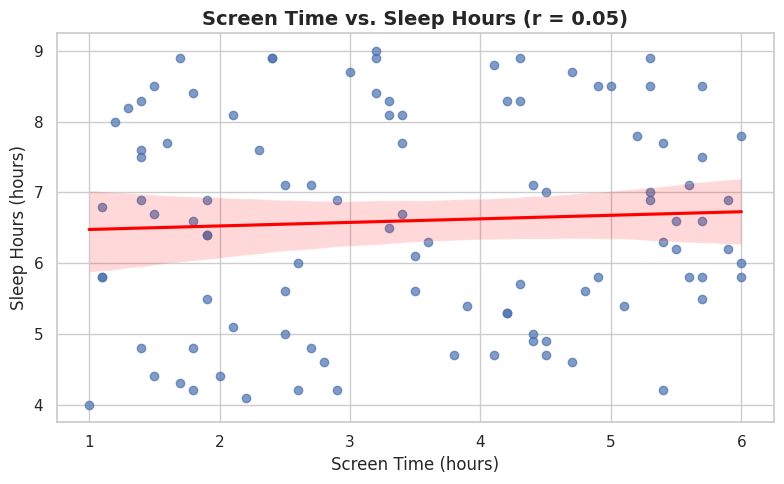

In [24]:
corr_screen_sleep = df_student['screen_time'].corr(df_student['sleep_hours'])
print(f"Correlation coefficient (r): {corr_screen_sleep:.4f}")

# Scatter plot with regression line to visualize the relationship
plt.figure(figsize=(8, 5))
sns.regplot(data=df_student, x='screen_time', y='sleep_hours', scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.title(f'Screen Time vs. Sleep Hours (r = {corr_screen_sleep:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Screen Time (hours)', fontsize=12)
plt.ylabel('Sleep Hours (hours)', fontsize=12)
plt.tight_layout()
plt.show()

**Answer (Q3):** **No**, there is virtually no linear relationship between screen time and sleep hours. The Pearson correlation coefficient is **$r = 0.0524$**, which is very close to zero, indicating no meaningful correlation in this dataset.

### Q4: Draw a histogram of daily transport cost.

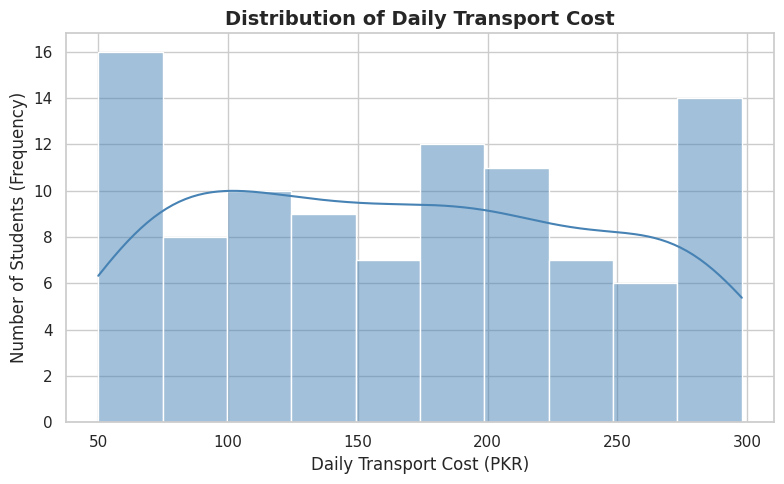

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_student, x='daily_transport_cost', bins=10, kde=True, color='steelblue')
plt.title('Distribution of Daily Transport Cost', fontsize=14, fontweight='bold')
plt.xlabel('Daily Transport Cost (PKR)', fontsize=12)
plt.ylabel('Number of Students (Frequency)', fontsize=12)
plt.tight_layout()
plt.show()

**Observation (Q4):** Daily transport costs range from **PKR 50.00** to **PKR 298.00**, with a mean of **PKR 168.26** and median of **PKR 169.50**, spread fairly evenly across the range.

### Q5: Compare average internet usage by gender.

   gender  internet_usage
0  Female        5.321154
1    Male        6.002083


/tmp/ipykernel_500/68624599.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=avg_internet_gender, x='gender', y='internet_usage', palette='pastel')


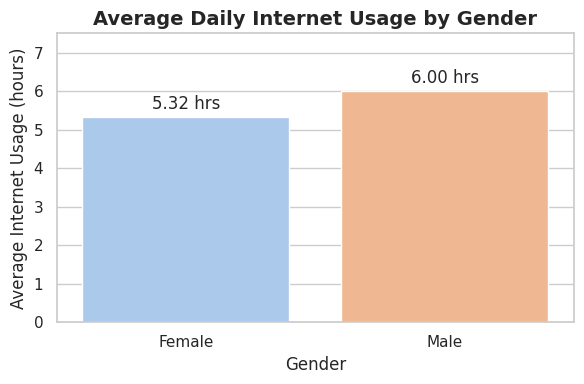

In [26]:
avg_internet_gender = df_student.groupby('gender')['internet_usage'].mean().reset_index()
print(avg_internet_gender)

plt.figure(figsize=(6, 4))
ax = sns.barplot(data=avg_internet_gender, x='gender', y='internet_usage', palette='pastel')
plt.title('Average Daily Internet Usage by Gender', fontsize=14, fontweight='bold')
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Average Internet Usage (hours)', fontsize=12)
plt.ylim(0, 7.5)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f hrs', padding=3)

plt.tight_layout()
plt.show()

**Answer (Q5):** **Males** have a higher average daily internet usage at **6.00 hours**, compared to **Females** at **5.32 hours** (a difference of 0.68 hours per day).